<a href="https://colab.research.google.com/github/sastha-06/24ADI006_DL_24BAD106/blob/main/24BAD106_DL_EX5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import requests
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
print("SASTHA JEYASRI A\n24BAD106")
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = requests.get(url).text.lower()

print("Dataset loaded successfully")
print(text[:500])
word = re.findall(r"[a-z']+", text)
tokenizer = Tokenizer()
tokenizer.fit_on_texts(word)
vocab_size = len(tokenizer.word_index) + 1
print("Total words:", len(word))
print("Vocabulary size:", vocab_size)
sequence = []
for i in range(1, min(len(word), 30000)):
    sequence.append(word[max(0, i-4):i+1])
sequence = tokenizer.texts_to_sequences(
    [" ".join(x) for x in sequence]
)
sequence = pad_sequences(
    sequence,
    maxlen=5,
    padding="pre"
)
X = sequence[:, :-1]
y = sequence[:, -1]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

SASTHA JEYASRI A
24BAD106
Dataset loaded successfully
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us kill him, and we'll have corn at our own price.
is't a verdict?

all:
no more talking on't; let it be done: away, away!

second citizen:
one word, good citizens.

first citizen:
we are accounted poor
Total words: 204062
Vocabulary size: 12632
Input shape: (29999, 4)
Target shape: (29999,)
Training shape: (23999, 4)
Validation shape: (6000, 4)


In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

print("SASTHA JEYASRI A\n24BAD106")

model = Sequential([
    Embedding(vocab_size, 64),
    SimpleRNN(64),
    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

SASTHA JEYASRI A
24BAD106


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

SASTHA JEYASRI A
24BAD106
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.0265 - loss: 9.4379 - val_accuracy: 0.0375 - val_loss: 9.4318
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.0372 - loss: 9.4252 - val_accuracy: 0.0375 - val_loss: 9.4189
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.0373 - loss: 9.4115 - val_accuracy: 0.0375 - val_loss: 9.4040
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.0373 - loss: 9.3940 - val_accuracy: 0.0375 - val_loss: 9.3828
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.0373 - loss: 9.3639 - val_accuracy: 0.0375 - val_loss: 9.3389
SGD completed
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - accuracy: 0.0355 - loss: 7.5229 - val_accuracy: 0.0375 - val_loss: 6.8239
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 76ms/step - accuracy: 0.0372 - loss: 6.7509 - val_accuracy: 0.0375 - val_loss: 6.7684
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - ac

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

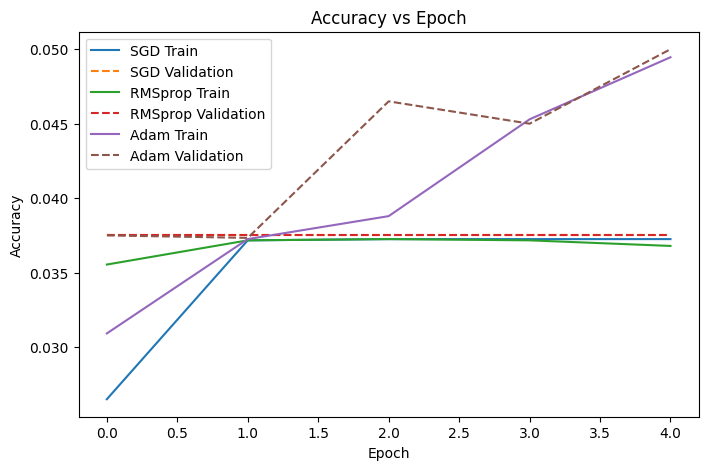

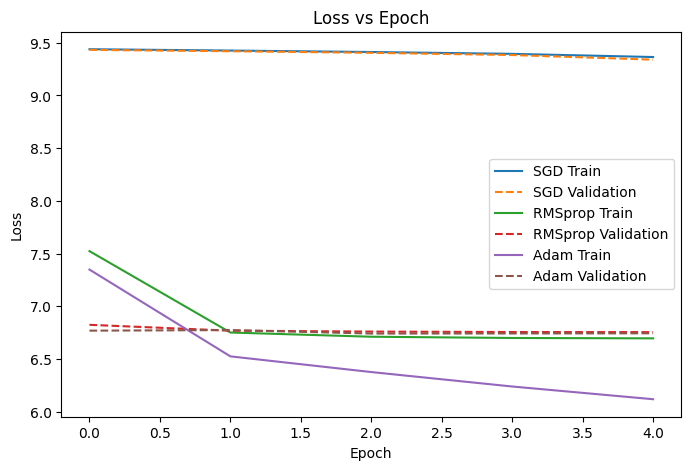


Optimizer: SGD
Training Accuracy: 0.0373
Validation Accuracy: 0.0375
Training Loss: 9.3639
Validation Loss: 9.3389

Optimizer: RMSprop
Training Accuracy: 0.0368
Validation Accuracy: 0.0375
Training Loss: 6.6956
Validation Loss: 6.7547

Optimizer: Adam
Training Accuracy: 0.0495
Validation Accuracy: 0.05
Training Loss: 6.1182
Validation Loss: 6.7433


In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt

print("SASTHA JEYASRI A\n24BAD106")
optimizers = {
    "SGD": tf.keras.optimizers.SGD(0.01),
    "RMSprop": tf.keras.optimizers.RMSprop(0.001),
    "Adam": tf.keras.optimizers.Adam(0.001)
}
histories = {}

for name, optimizer in optimizers.items():

    m = Sequential([
        Embedding(vocab_size, 64),
        SimpleRNN(64),
        Dense(vocab_size, activation="softmax")
    ])

    m.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    histories[name] = m.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=5,
        batch_size=128,
        verbose=1
    )

    print(name, "completed")

    plt.figure(figsize=(8,5))

for name, h in histories.items():
    plt.plot(h.history["accuracy"], label=name + " Train")
    plt.plot(h.history["val_accuracy"], "--", label=name + " Validation")

plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8,5))

for name, h in histories.items():
    plt.plot(h.history["loss"], label=name + " Train")
    plt.plot(h.history["val_loss"], "--", label=name + " Validation")

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

for name, h in histories.items():

    print("\nOptimizer:", name)
    print("Training Accuracy:", round(h.history["accuracy"][-1], 4))
    print("Validation Accuracy:", round(h.history["val_accuracy"][-1], 4))
    print("Training Loss:", round(h.history["loss"][-1], 4))
    print("Validation Loss:", round(h.history["val_loss"][-1], 4))

In [6]:
import numpy as np
print("SASTHA JEYASRI A\n24BAD106")

model = Sequential([
    Embedding(vocab_size, 64),
    SimpleRNN(64),
    Dense(vocab_size, activation="softmax")
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)
reverse_words = {v: k for k, v in tokenizer.word_index.items()}
def generate_text(seed, n=10):
    words = seed.lower().split()
    for _ in range(n):
        seq = tokenizer.texts_to_sequences(
            [" ".join(words[-4:])]
        )
        seq = pad_sequences(
            seq,
            maxlen=4,
            padding="pre"
        )
        prediction = model.predict(seq, verbose=0)
        next_word = reverse_words.get(
            np.argmax(prediction[0]),
            ""
        )
        words.append(next_word)

    return " ".join(words)
    print("Sample 1:")
print(generate_text("to be or not", 10))

print("\nSample 2:")
print(generate_text("the king", 10))

print("\nSample 3:")
print(generate_text("my lord", 10))

SASTHA JEYASRI A
24BAD106
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 24s 101ms/step - accuracy: 0.0342 - loss: 7.3323 - val_accuracy: 0.0375 - val_loss: 6.7607
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 72ms/step - accuracy: 0.0373 - loss: 6.5142 - val_accuracy: 0.0375 - val_loss: 6.7465
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.0408 - loss: 6.3576 - val_accuracy: 0.0453 - val_loss: 6.7433
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.0445 - loss: 6.2238 - val_accuracy: 0.0447 - val_loss: 6.7426
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 76ms/step - accuracy: 0.0510 - loss: 6.1055 - val_accuracy: 0.0487 - val_loss: 6.7378
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 76ms/step - accuracy: 0.0550 - loss: 5.9869 - val_accuracy: 0.0505 - val_loss: 6.7698
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.0606 - loss: 5.8602 - val_accuracy: 0.0540 - val_loss: 6.7902
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 70ms/step - accurac